Install the required libraries

---



In [ ]:
from google.colab import output
%pip install -q pandas scikit-learn matplotlib seaborn joblib gradio
output.clear()

In [ ]:
import nltk
import pandas as pd
import matplotlib.pyplot as plt

nltk.download("movie_reviews", quiet=True)

from nltk.corpus import movie_reviews

rows = []

for label in movie_reviews.categories():
    for file_id in movie_reviews.fileids(categories=[label]):
        review = " ".join(movie_reviews.words(file_id))
        rows.append({
            "review": review,
            "sentiment": label
        })

df = pd.DataFrame(rows)

# Convert labels into readable names
df["sentiment"] = df["sentiment"].map({
    "pos": "positive",
    "neg": "negative"
})

print("Dataset shape:", df.shape)
print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())
print("\nClass distribution:")
print(df["sentiment"].value_counts())

df.head()

Dataset shape: (2000, 2)

Missing values:
review       0
sentiment    0
dtype: int64

Duplicate rows: 0

Class distribution:
sentiment
negative    1000
positive    1000
Name: count, dtype: int64


,review,sentiment
0,"plot : two teen couples go to a church party ,...",negative
1,the happy bastard ' s quick movie review damn ...,negative
2,it is movies like these that make a jaded movi...,negative
3,""" quest for camelot "" is warner bros . ' first...",negative
4,synopsis : a mentally unstable man undergoing ...,negative


Clean dataset shape: (2000, 2)


,review,sentiment
1860,the verdict : spine - chilling drama from horr...,positive
353,""" the 44 caliber killer has struck again . "" s...",negative
1333,in the company of men made a splash at the sun...,positive
905,"in the year 2029 , captain leo davidson ( mark...",negative
1289,[ note that followups are directed to rec . ar...,positive


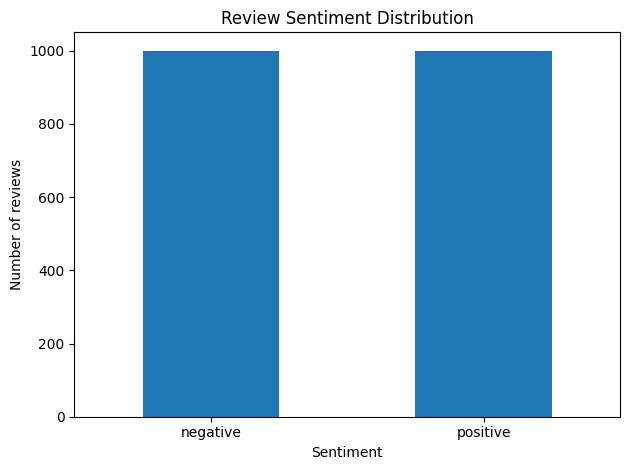

In [ ]:
# Remove missing and empty reviews
df = df.dropna(subset=["review", "sentiment"]).copy()
df["review"] = df["review"].astype(str).str.strip()
df = df[df["review"] != ""]

# Remove exact duplicate review/label pairs
df = df.drop_duplicates(subset=["review", "sentiment"])
df = df.reset_index(drop=True)

print("Clean dataset shape:", df.shape)
display(df.sample(5, random_state=42))

# Visualize the class distribution
df["sentiment"].value_counts().plot(
    kind="bar",
    title="Review Sentiment Distribution",
    xlabel="Sentiment",
    ylabel="Number of reviews",
    rot=0
)
plt.tight_layout()
plt.show()

# Save the cleaned dataset
df.to_csv("reviews_cleaned.csv", index=False)

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

X = df["review"]
y = df["sentiment"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

model = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        strip_accents="unicode",
        ngram_range=(1, 2),
        max_features=30000,
        min_df=2,
        sublinear_tf=True
    )),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

model.fit(X_train, y_train)

print("Training examples:", len(X_train))
print("Testing examples:", len(X_test))
print("Model training completed.")

Training examples: 1600
Testing examples: 400
Model training completed.


Test accuracy: 0.8625 (86.25%)

Classification report:
              precision    recall  f1-score   support

    negative       0.86      0.86      0.86       200
    positive       0.86      0.86      0.86       200

    accuracy                           0.86       400
   macro avg       0.86      0.86      0.86       400
weighted avg       0.86      0.86      0.86       400



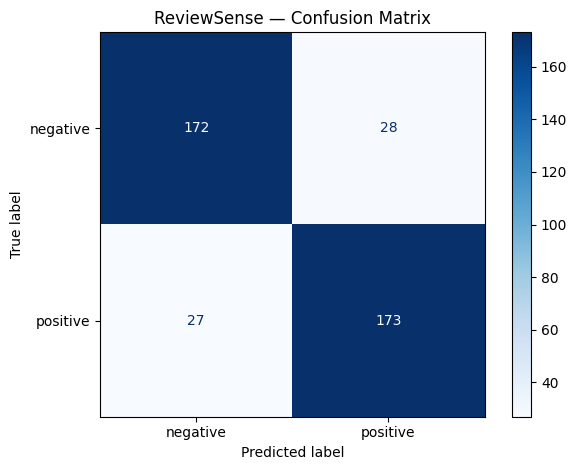

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
    confusion_matrix
)

y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print(f"Test accuracy: {accuracy:.4f} ({accuracy * 100:.2f}%)")
print("\nClassification report:")
print(classification_report(y_test, y_pred, zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=["negative", "positive"],
    cmap="Blues"
)
plt.title("ReviewSense — Confusion Matrix")
plt.tight_layout()
plt.show()

In [ ]:
errors = pd.DataFrame({
    "review": X_test.reset_index(drop=True),
    "actual": y_test.reset_index(drop=True),
    "predicted": y_pred
})

errors = errors[errors["actual"] != errors["predicted"]]

print("Number of incorrect predictions:", len(errors))

if len(errors) >= 5:
    display(errors.head(5))
else:
    display(errors)
    print("Fewer than five errors occurred; inspect all available errors.")

Number of incorrect predictions: 55


,review,actual,predicted
3,running time approximately 1hr 40mins reviewed...,negative,positive
10,in the line of duty is the critically praised ...,negative,positive
11,""" take a number , fill out a form , and wait y...",positive,negative
22,""" the blair witch project "" was perhaps one of...",positive,negative
23,let ' s face it : since waterworld floated by ...,positive,negative


In [ ]:
def predict_sentiment(review):
    if not isinstance(review, str) or not review.strip():
        return {
            "error": "Please enter a non-empty review."
        }

    prediction = model.predict([review])[0]

    return {
        "sentiment": prediction
    }


test_reviews = [
    "This movie was wonderful and entertaining.",
    "The movie was boring and disappointing.",
    "The story was not good at all.",
    "",
]

for review in test_reviews:
    print("Review:", repr(review))
    print("Prediction:", predict_sentiment(review))
    print("-" * 60)

Review: 'This movie was wonderful and entertaining.'
Prediction: {'sentiment': 'positive'}
------------------------------------------------------------
Review: 'The movie was boring and disappointing.'
Prediction: {'sentiment': 'negative'}
------------------------------------------------------------
Review: 'The story was not good at all.'
Prediction: {'sentiment': 'negative'}
------------------------------------------------------------
Review: ''
Prediction: {'error': 'Please enter a non-empty review.'}
------------------------------------------------------------


In [ ]:
import gradio as gr

def review_sense_app(review):
    result = predict_sentiment(review)

    if "error" in result:
        return result["error"]

    sentiment = result["sentiment"]

    if sentiment == "positive":
        return "Positive sentiment — the review is classified as positive."

    return "Negative sentiment — the review is classified as negative."


demo = gr.Interface(
    fn=review_sense_app,
    inputs=gr.Textbox(
        lines=5,
        label="Customer review",
        placeholder="Type a review here..."
    ),
    outputs=gr.Textbox(label="ReviewSense prediction"),
    title="ReviewSense",
    description=(
        "A machine-learning sentiment classifier. "
        "Enter a review to predict whether its sentiment is positive or negative."
    ),
    examples=[
        ["This movie was wonderful and entertaining."],
        ["The movie was boring and disappointing."],
        ["The acting was good but the story was terrible."]
    ]
)

demo.launch(share=True, debug=False)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()

Could not create share link. Please check your internet connection or our status page: https://status.gradio.app.


2026/10/29 10:00:53 [W] [service.go:132] login to server failed: dial tcp 44.237.78.176:7000: connect: connection refused


<IPython.core.display.Javascript object>

In [ ]:
import joblib
import os

os.makedirs("ReviewSense", exist_ok=True)

joblib.dump(model, "ReviewSense/reviewsense_model.joblib")

df.to_csv("ReviewSense/reviews_cleaned.csv", index=False)

print("Model and cleaned dataset saved.")

Model and cleaned dataset saved.


In [ ]:
import sklearn
print("scikit-learn version:", sklearn.__version__)
print("joblib version:", joblib.__version__)

scikit-learn version: 1.6.1
joblib version: 1.6.0
